# Régression logistique : Iris

## Objectif

Nous allons construire un modèle simple pour répondre à la question :

**Cette fleur est-elle une Iris Setosa ?**

La variable cible sera :

- `1` : Setosa
- `0` : autre espèce

Pour commencer, nous utiliserons seulement deux variables :

- longueur du pétale ;
- largeur du pétale.

Cela permet de visualiser facilement les données et la frontière de décision du modèle.

## 1. Importer les bibliothèques

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

RANDOM_STATE = 42

## 2. Charger le jeu de données Iris

In [21]:
iris = load_iris(as_frame=True)

df = iris.frame.copy()

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Le jeu de données Iris contient plusieurs mesures sur des fleurs appartenant à trois espèces :

- Setosa ;
- Versicolor ;
- Virginica.

Pour cette introduction, nous transformons le problème en **classification binaire** : Setosa contre non-Setosa.

In [22]:
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

df[["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)", "species"]].head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Créer la variable cible

In [23]:
df["is_setosa"] = (df["species"] == "setosa").astype(int)

df[["species", "is_setosa"]].head(10)

,species,is_setosa
0,setosa,1
1,setosa,1
2,setosa,1
3,setosa,1
4,setosa,1
5,setosa,1
6,setosa,1
7,setosa,1
8,setosa,1
9,setosa,1


In [24]:
df["is_setosa"].value_counts()

is_setosa
0    100
1     50
Name: count, dtype: int64

La cible prend uniquement deux valeurs :

- `0` : la fleur n'est pas Setosa ;
- `1` : la fleur est Setosa.

## 4. Visualiser les données

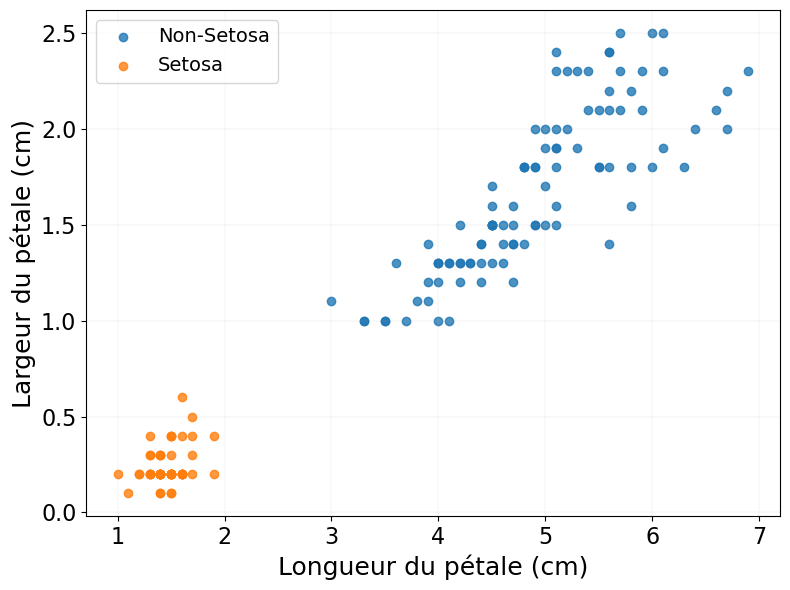

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))

for value, label in [(0, "Non-Setosa"), (1, "Setosa")]:
    subset = df[df["is_setosa"] == value]

    ax.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=label,
        alpha=0.8
    )

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Longueur du pétale (cm)", fontsize=18)
plt.ylabel("Largeur du pétale (cm)", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

On voit déjà que les fleurs Setosa occupent une région différente des autres fleurs.

C'est exactement le type de problème que la régression logistique peut traiter.

## 5. Définir les variables explicatives et la cible

In [26]:
features = [
    "petal length (cm)",
    "petal width (cm)"
]

X = df[features]
y = df["is_setosa"]

print("X :", X.shape)
print("y :", y.shape)

X : (150, 2)
y : (150,)


## 6. Séparer les données d'entraînement et de test

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)

Entraînement : (112, 2)
Test : (38, 2)


Nous utilisons une partie des données pour entraîner le modèle et une autre partie pour évaluer ses performances.

## 7. Entraîner une régression logistique

La régression logistique calcule d'abord une combinaison linéaire :

$z = b + w_1x_1 + w_2x_2$


Puis elle applique la fonction sigmoïde :


$p = \frac{1}{1 + e^{-z}}$


La valeur obtenue peut être interprétée comme une probabilité.

In [28]:
model = LogisticRegression()

model.fit(X_train, y_train)

print("Modèle entraîné.")

Modèle entraîné.


## 8. Prédire des probabilités

In [29]:
y_prob = model.predict_proba(X_test)[:, 1]

results = X_test.copy()
results["Observation"] = y_test.values
results["Probabilite_Setosa"] = y_prob

results.head(10)

,petal length (cm),petal width (cm),Observation,Probabilite_Setosa
51,4.5,1.5,0,0.005693
110,5.1,2.0,0,0.000788
52,4.9,1.5,0,0.002138
73,4.7,1.2,0,0.004727
134,5.6,1.4,0,0.000425
137,5.5,1.8,0,0.000362
34,1.5,0.2,1,0.971482
41,1.3,0.3,1,0.980510
7,1.5,0.2,1,0.971482
32,1.5,0.1,1,0.974164


La colonne `Probabilite_Setosa` correspond à la probabilité estimée que la fleur soit une Setosa.

## 9. Transformer la probabilité en classe

Avec un seuil de `0.5` :

$
\hat{y} =
\begin{cases}
1 & \text{si } p \geq 0.5 \\
0 & \text{si } p < 0.5
\end{cases}
$

In [30]:
threshold = 0.9

y_pred = (y_prob >= threshold).astype(int)

results["Prediction"] = y_pred

results.head(10)

,petal length (cm),petal width (cm),Observation,Probabilite_Setosa,Prediction
51,4.5,1.5,0,0.005693,0
110,5.1,2.0,0,0.000788,0
52,4.9,1.5,0,0.002138,0
73,4.7,1.2,0,0.004727,0
134,5.6,1.4,0,0.000425,0
137,5.5,1.8,0,0.000362,0
34,1.5,0.2,1,0.971482,1
41,1.3,0.3,1,0.980510,1
7,1.5,0.2,1,0.971482,1
32,1.5,0.1,1,0.974164,1


## 10. Visualiser la frontière de décision

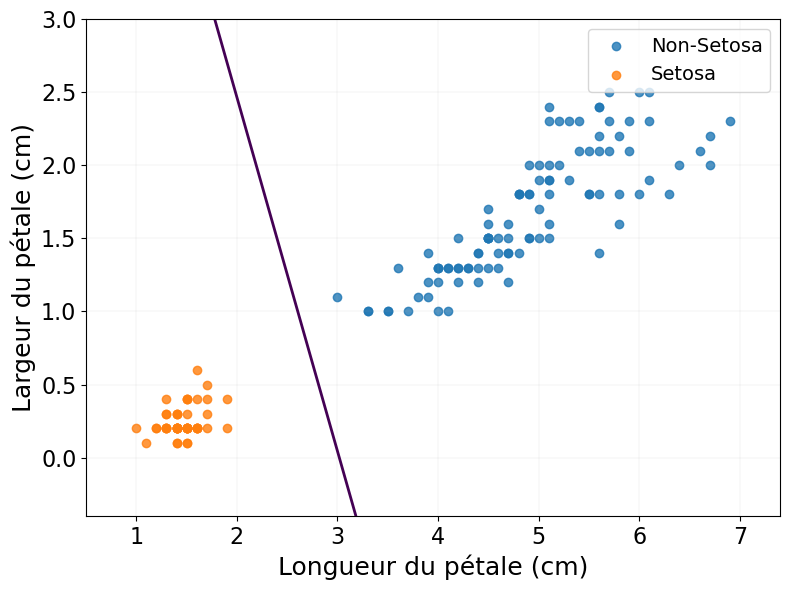

In [31]:
x_min = X["petal length (cm)"].min() - 0.5
x_max = X["petal length (cm)"].max() + 0.5

y_min = X["petal width (cm)"].min() - 0.5
y_max = X["petal width (cm)"].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    "petal length (cm)": xx.ravel(),
    "petal width (cm)": yy.ravel()
})

grid_prob = model.predict_proba(grid)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))

ax.contour(
    xx,
    yy,
    grid_prob,
    levels=[0.5],
    linewidths=2
)

for value, label in [(0, "Non-Setosa"), (1, "Setosa")]:
    subset = df[df["is_setosa"] == value]

    ax.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=label,
        alpha=0.8
    )

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Longueur du pétale (cm)", fontsize=18)
plt.ylabel("Largeur du pétale (cm)", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

La ligne représente la frontière correspondant à une probabilité de `0.5`.

D'un côté, le modèle prédit Setosa. De l'autre, il prédit non-Setosa.

## 11. Matrice de confusion

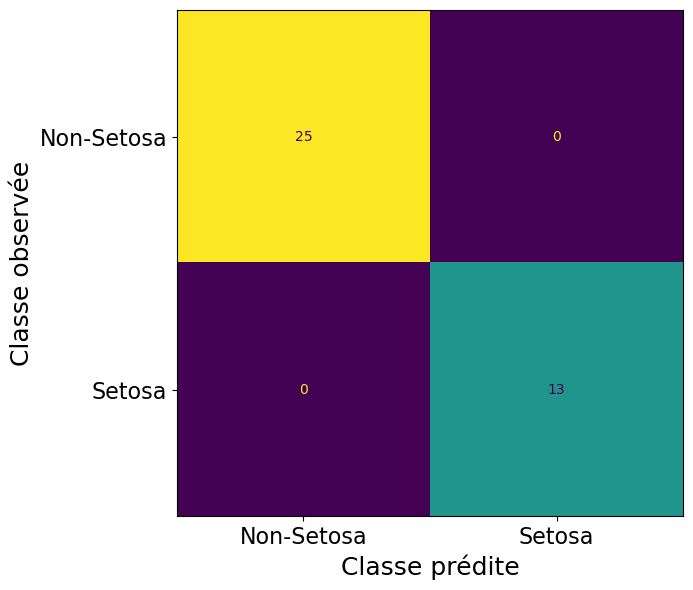

In [32]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Setosa", "Setosa"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel("Classe prédite", fontsize=18)
plt.ylabel("Classe observée", fontsize=18)
plt.grid(False)

plt.tight_layout()
plt.show()

La matrice de confusion permet de voir :

- les vrais positifs ;
- les vrais négatifs ;
- les faux positifs ;
- les faux négatifs.

## 12. Calculer les métriques

In [33]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metrics = pd.DataFrame({
    "Métrique": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Valeur": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

metrics

,Métrique,Valeur
0,Accuracy,1.0
1,Precision,1.0
2,Recall,1.0
3,F1-score,1.0


### Accuracy

\[
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
\]

Quelle proportion de toutes les prédictions est correcte ?

### Precision

\[
Precision = \frac{TP}{TP + FP}
\]

Parmi les fleurs prédites Setosa, combien sont réellement Setosa ?

### Recall

\[
Recall = \frac{TP}{TP + FN}
\]

Parmi toutes les vraies Setosa, combien sont détectées ?

### F1-score

\[
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
\]

Le F1-score combine precision et recall.

## 13. Changer le seuil de classification

In [34]:
thresholds = [0.2, 0.4, 0.5, 0.6, 0.8]

rows = []

for threshold in thresholds:
    pred = (y_prob >= threshold).astype(int)

    rows.append({
        "Seuil": threshold,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })

threshold_results = pd.DataFrame(rows)

threshold_results

,Seuil,Accuracy,Precision,Recall,F1-score
0,0.2,1.0,1.0,1.0,1.0
1,0.4,1.0,1.0,1.0,1.0
2,0.5,1.0,1.0,1.0,1.0
3,0.6,1.0,1.0,1.0,1.0
4,0.8,1.0,1.0,1.0,1.0


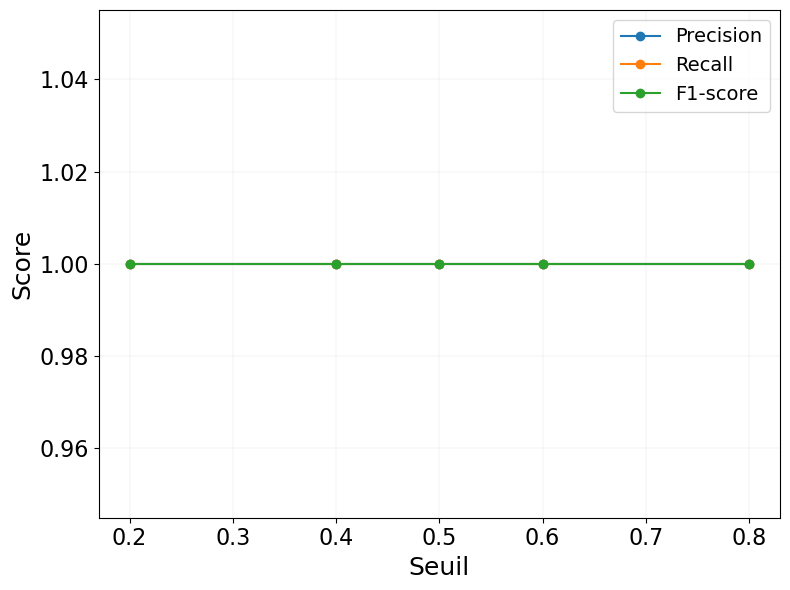

In [35]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    threshold_results["Seuil"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    threshold_results["Seuil"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

ax.plot(
    threshold_results["Seuil"],
    threshold_results["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Seuil", fontsize=18)
plt.ylabel("Score", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

Changer le seuil peut modifier :

- le nombre de prédictions positives ;
- la precision ;
- le recall ;
- le nombre de faux positifs ;
- le nombre de faux négatifs.

Dans ce jeu de données simple, la séparation est très nette, donc les différences peuvent être faibles.

## 14. Courbe ROC

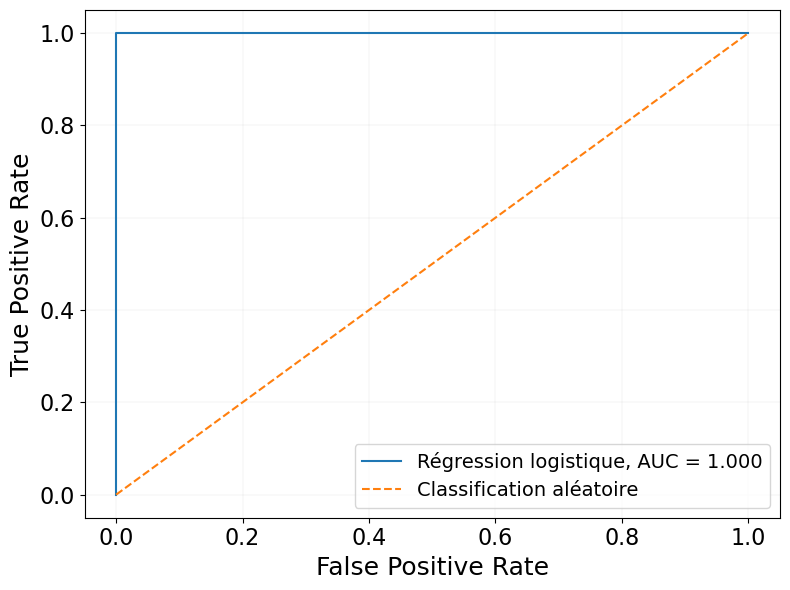

In [36]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    fpr,
    tpr,
    label=f"Régression logistique, AUC = {auc:.3f}"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Classification aléatoire"
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("False Positive Rate", fontsize=18)
plt.ylabel("True Positive Rate", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

La courbe ROC montre le compromis entre :

- True Positive Rate ;
- False Positive Rate.

L'AUC mesure la capacité du modèle à séparer les deux classes.

- `AUC = 0.5` : modèle équivalent à un classement aléatoire ;
- `AUC = 1` : séparation parfaite.

## 15. Regarder les coefficients du modèle

In [37]:
coef_df = pd.DataFrame({
    "Variable": features,
    "Coefficient": model.coef_[0]
})

coef_df

,Variable,Coefficient
0,petal length (cm),-2.457077
1,petal width (cm),-1.015329


Un coefficient :

- positif augmente la probabilité prédite de la classe `1` ;
- négatif diminue la probabilité prédite de la classe `1`.

Ici, la classe `1` correspond à Setosa.

## 16. Faire une prédiction manuelle

In [38]:
new_flower = pd.DataFrame({
    "petal length (cm)": [1.5],
    "petal width (cm)": [0.3]
})

probability = model.predict_proba(new_flower)[0, 1]
prediction = model.predict(new_flower)[0]

print(f"Probabilité Setosa : {probability:.3f}")
print(f"Classe prédite     : {prediction}")

Probabilité Setosa : 0.969
Classe prédite     : 1


Vous pouvez modifier la longueur et la largeur du pétale et observer comment la prédiction change.

## 17. Résumé

Dans ce notebook :

1. nous avons transformé Iris en problème de classification binaire ;
2. la régression logistique a produit une probabilité ;
3. un seuil de classification a transformé la probabilité en classe ;
4. nous avons visualisé la frontière de décision ;
5. nous avons utilisé une matrice de confusion ;
6. nous avons calculé accuracy, precision, recall et F1-score ;
7. nous avons étudié l'effet du seuil ;
8. nous avons calculé une courbe ROC et l'AUC.

## 18. Exercices

### Exercice 1

Changez le seuil de `0.5` à `0.3`.

Comparez :

- accuracy ;
- precision ;
- recall ;
- matrice de confusion.

### Exercice 2

Changez le seuil à `0.8`.

Que se passe-t-il ?

### Exercice 3

Remplacez les deux variables par :

- `sepal length (cm)` ;
- `sepal width (cm)`.

Réentraînez le modèle.

La classification est-elle toujours aussi facile ?

### Exercice 4

Utilisez les quatre variables disponibles :

- sepal length ;
- sepal width ;
- petal length ;
- petal width.

Comparez les résultats avec le modèle utilisant seulement les deux variables sur les pétales.

### Exercice 5

Créez votre propre fleur et demandez au modèle si elle est Setosa.